# Fitting models to data

This tutorial fits dynamical models to data with `braintools.fit`. The data are simulated from models with known parameters, so every fit can be checked against the truth:

1. **Simulate** a Hopf (Stuart–Landau) oscillator with `braintools.quad.odeint` (fixed step) and `solve_ivp` (adaptive step).
2. **Fit** its bifurcation parameter and frequency with a `Fitter` and a composed `Objective`, from 8 starting points minimised at once.
3. **Check** the fit: the loss landscape with `fit.sweep`, and confidence intervals with `fit.hessian_ci`.
4. **Fit a module**: recover the couplings of a Wilson–Cowan model written as a `brainstate` module with `brainstate.nn.Param` parameters.
5. **Losses for spiking data**, and **saving** results to HDF5.

In [1]:
import os
import tempfile

import brainstate
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from braintools import fit, quad
from braintools.fit import Fitter, Term, losses

## 1. Simulating trajectories

The Stuart–Landau oscillator is the normal form of a Hopf bifurcation:

$$\dot x = (a - x^2 - y^2)\,x - \omega y, \qquad \dot y = (a - x^2 - y^2)\,y + \omega x.$$

For $a > 0$ the trajectory settles on a limit cycle of radius $\sqrt a$ that rotates at angular frequency $\omega$. `quad.odeint(f, y0, t0, t1, dt, *args)` integrates it with any registered stepper (`method='rk4'` by default) as one compiled `scan`, and returns the time grid and the stacked states. Extra positional arguments are passed through to `f`.

In [2]:
def hopf(y, t, a, omega):
    x, v = y
    r2 = x * x + v * v
    return (a - r2) * x - omega * v, (a - r2) * v + omega * x

y0 = (jnp.asarray(0.5), jnp.asarray(0.0))
ts, (xs, vs) = quad.odeint(hopf, y0, 0.0, 10.0, 0.05, 0.8, 1.5)
print(ts.shape, xs.shape)

(201,) (201,)


`quad.solve_ivp` integrates the same system with an adaptive step size (Dormand–Prince 5(4) with a PI step-size controller). With `t_eval` it returns the solution at the requested times; here the two solvers agree to within a few $10^{-6}$:

In [3]:
sol = quad.solve_ivp(hopf, (0.0, 10.0), y0, 0.8, 1.5, rtol=1e-8, atol=1e-10, t_eval=ts)
print('accepted steps:', int(sol.n_steps), ' rejected:', int(sol.n_rejected), ' success:', bool(sol.success))
print('max |odeint - solve_ivp| =', float(jnp.max(jnp.abs(sol.ys[0] - xs))))

accepted steps: 295  rejected: 96  success: True
max |odeint - solve_ivp| = 2.8461217880249023e-06


The observed data are the $x$ trace with measurement noise. The truth is $a = 0.8$, $\omega = 1.5$.

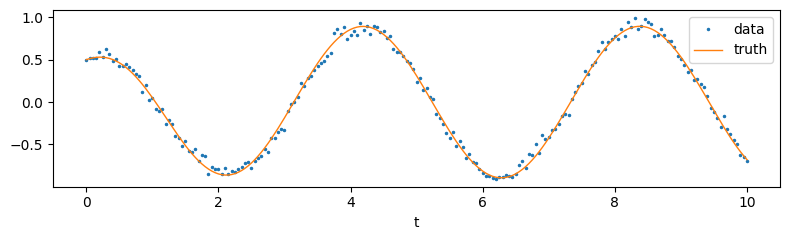

In [4]:
truth = {'a': 0.8, 'omega': 1.5}

def simulate(params):
    _, (x, _) = quad.odeint(hopf, y0, 0.0, 10.0, 0.05, params['a'], params['omega'])
    return x

noise = 0.05 * jax.random.normal(jax.random.PRNGKey(1), xs.shape)
data = simulate(truth) + noise

plt.figure(figsize=(8, 2.5))
plt.plot(ts, data, '.', ms=3, label='data')
plt.plot(ts, simulate(truth), lw=1, label='truth')
plt.xlabel('t'); plt.legend(); plt.tight_layout()

## 2. Fitting with a `Fitter`

A fit needs three things:

- a pure `simulate(params)` function of a dict of parameters;
- an objective `objective(prediction, target) -> scalar`;
- a search space `{name: (low, high)}`.

Objectives compose from `Term`s with `+` and scalar `*`. Here the loss is the mean squared error plus a small correlation term, which rewards getting the phase right even when the amplitude is off. `Objective.breakdown` reports each term:

In [5]:
objective = Term(losses.mse, name='mse') + 0.1 * Term(losses.correlation_loss, name='corr')
print(objective)
print({k: round(float(v), 4) for k, v in objective.breakdown(simulate(truth), data).items()})

Objective(1.0*mse + 0.1*corr)


{'mse': 0.0029, 'corr': 0.0004}


`Fitter.fit(target, n_starts=8, key=...)` draws 8 starting points uniformly inside the bounds and minimises all of them at once: the default `'grad'` backend runs L-BFGS on every start inside one compiled, vmapped loop. Each bounded parameter is optimised in an unconstrained space through a sigmoid, so the iterates always stay inside the box.

In [6]:
space = {'a': (0.2, 2.0), 'omega': (0.5, 3.0)}
fitter = Fitter(simulate, objective, space)
res = fitter.fit(data, n_starts=8, key=jax.random.PRNGKey(0), n_steps=200)

print(res)
print({k: round(float(v), 4) for k, v in res.best_params.items()}, ' truth:', truth)
print('final loss per start:', np.round(np.asarray(res.losses), 4))

FitResult(backend='grad', best_loss=0.00329198, n_starts=8, params=[a, omega])
{'a': 0.7886, 'omega': 1.5008}  truth: {'a': 0.8, 'omega': 1.5}
final loss per start: [0.5226 0.5167 0.0033 0.0033 0.0033 0.0033 0.5167 0.5109]


The final losses show why several starts are needed. Every start that ends at loss ≈ 0.003, the floor set by the measurement noise (variance $0.05^2 = 0.0025$), found the truth. The others end near 0.52: with the wrong frequency, the best they can do is shrink the oscillation, so they run to the lower bound of $a$. `res.history` holds the loss of every start at every iteration:

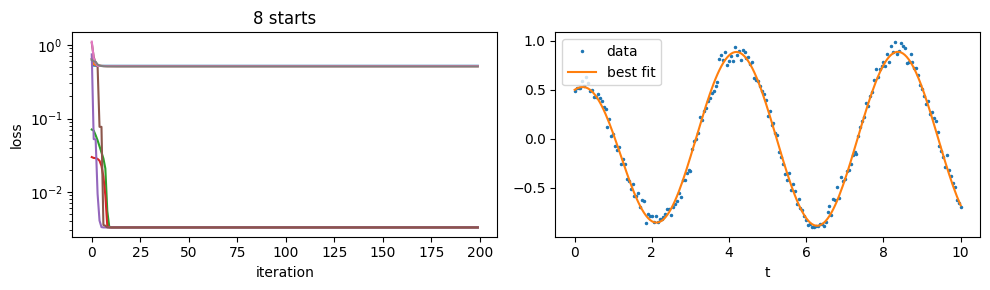

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].semilogy(np.asarray(res.history).T)
axes[0].set_xlabel('iteration'); axes[0].set_ylabel('loss'); axes[0].set_title('8 starts')
axes[1].plot(ts, data, '.', ms=3, label='data')
axes[1].plot(ts, simulate(res.best_params), lw=1.5, label='best fit')
axes[1].set_xlabel('t'); axes[1].legend()
plt.tight_layout()

## 3. Checking the fit

### The loss landscape

`fit.sweep(fn, grid)` evaluates a pure function over a parameter grid. `mode='product'` evaluates the cartesian product, and `batch_size` evaluates the points in vmapped chunks, so memory stays bounded. Here it maps the loss over 60 × 60 values of $(a, \omega)$:

(60, 60)


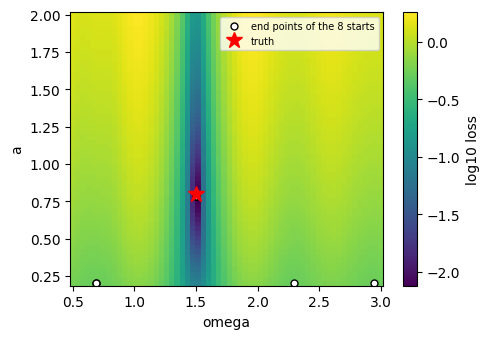

In [8]:
grid = {'a': jnp.linspace(0.2, 2.0, 60), 'omega': jnp.linspace(0.5, 3.0, 60)}
landscape, table = fit.sweep(lambda p: objective(simulate(p), data), grid, batch_size=400)
print(landscape.shape)

plt.figure(figsize=(5, 3.5))
plt.pcolormesh(grid['omega'], grid['a'], jnp.log10(landscape), shading='auto')
plt.colorbar(label='log10 loss')
starts = res.params
plt.plot(starts['omega'], starts['a'], 'wo', ms=5, mec='k', label='end points of the 8 starts')
plt.plot(truth['omega'], truth['a'], 'r*', ms=12, label='truth')
plt.xlabel('omega'); plt.ylabel('a'); plt.legend(fontsize=7, loc='upper right'); plt.tight_layout()

The loss has one narrow valley at the true frequency and is almost flat elsewhere. A start whose $\omega$ lies outside the valley gets almost no gradient towards it, so it lowers the loss by shrinking the amplitude instead and ends at the lower bound of $a$ (the white dots). Several starts make it likely that at least one begins inside the valley.

### Confidence intervals

`fit.hessian_ci` turns the curvature of the loss at the optimum into confidence intervals. With `kind='sse'`, the loss is a sum of squared residuals over `n_data` points. For a linear model these are exactly the ordinary-least-squares intervals. Here the 95% intervals are narrow and contain the truth:

In [9]:
sse = lambda p: jnp.sum((simulate(p) - data) ** 2)
ci = fit.hessian_ci(sse, res.best_params, kind='sse', n_data=data.size)
for name in ('a', 'omega'):
    print(f"{name:6s} {float(ci.estimate[name]):.4f} ± {float(ci.stderr[name]):.4f}   "
          f"95% CI [{float(ci.low[name]):.4f}, {float(ci.high[name]):.4f}]   truth {truth[name]}")

a      0.7886 ± 0.0100   95% CI [0.7688, 0.8083]   truth 0.8
omega  1.5008 ± 0.0010   95% CI [1.4988, 1.5027]   truth 1.5


## 4. Fitting a `brainstate` module

Models are usually written as `brainstate` modules. `Fitter.from_module(model, predict, objective)` fits every `brainstate.nn.Param` with `fit=True` (the default). Each parameter's own transform, here `SigmoidT(5, 20)`, sets its bounds.

During the fit the model is not modified. The best values are written back into the parameters only when `fit` returns.

The model is a two-population Wilson–Cowan network driven by a slow sinusoid; we recover the excitatory-to-excitatory and inhibitory-to-excitatory couplings from the simulated rates.

In [10]:
def sigmoid(x, gain, theta):
    return 1. / (1. + jnp.exp(-gain * (x - theta)))


class WilsonCowan(brainstate.nn.Module):
    def __init__(self, w_ee, w_ei):
        super().__init__()
        self.w_ee = brainstate.nn.Param(w_ee, t=brainstate.nn.SigmoidT(5., 20.))
        self.w_ei = brainstate.nn.Param(w_ei, t=brainstate.nn.SigmoidT(5., 20.))
        self.w_ie, self.w_ii = 13., 11.

    def rhs(self, y, t, w_ee, w_ei):
        e, i = y
        drive = 1.5 + jnp.sin(0.5 * t)
        de = -e + sigmoid(w_ee * e - w_ei * i + drive, 1.3, 4.)
        di = (-i + sigmoid(self.w_ie * e - self.w_ii * i, 2., 3.7)) / 2.
        return de, di

    def rates(self):
        y0 = (jnp.asarray(0.1), jnp.asarray(0.05))
        _, (e, i) = quad.odeint(self.rhs, y0, 0.0, 40.0, 0.1, self.w_ee.value(), self.w_ei.value())
        return jnp.stack([e, i], axis=-1)


target = WilsonCowan(16., 12.).rates()
model = WilsonCowan(10., 8.)          # wrong initial couplings
res_wc = Fitter.from_module(model, lambda m: m.rates(), losses.mse).fit(
    target, n_starts=8, key=jax.random.PRNGKey(0), n_steps=200)
print({k: round(float(v), 3) for k, v in res_wc.best_params.items()}, ' truth: w_ee=16, w_ei=12')
print('written back to the model:', round(float(model.w_ee.value()), 3), round(float(model.w_ei.value()), 3))

{'w_ee': 16.0, 'w_ei': 12.0}  truth: w_ee=16, w_ei=12
written back to the model: 16.0 12.0


The other backends take the same problem. `backend='scipy'` runs `scipy.optimize.minimize` from each start with jit-compiled gradients. `backend='nevergrad'` runs a gradient-free evolutionary search that evaluates each generation as one vmapped batch. Here is SciPy's L-BFGS-B on the Hopf fit:

In [11]:
res_scipy = Fitter(simulate, objective, space, backend='scipy').fit(
    data, n_starts=8, key=jax.random.PRNGKey(0), n_steps=200)
print(res_scipy.backend, {k: round(float(v), 4) for k, v in res_scipy.best_params.items()})

scipy {'a': 0.7886, 'omega': 1.5008}


## 5. Losses for spiking data, and saving results

`braintools.fit.losses` also compares spiking activity:

- `rate_loss` compares mean firing rates;
- `cv_loss` compares ISI irregularity;
- `van_rossum_loss` gives the van Rossum distance between dense rasters. It is differentiable, so gradients flow through surrogate-gradient spikes.

Each loss's docstring states whether it is differentiable.

In [12]:
from braintools import surrogate

dt = 0.1
t = jnp.arange(2000) * dt                                          # 200 ms
target_raster = (jnp.sin(2 * jnp.pi * t / 25.0)[:, None] > 0.995).astype(float) * jnp.ones((1, 3))

def raster(shift):
    # a surrogate spike: Heaviside forward, sigmoid gradient backward
    return surrogate.sigmoid(jnp.sin(2 * jnp.pi * (t[:, None] - shift) / 25.0) - 0.995) * jnp.ones((1, 3))

loss = lambda s: losses.van_rossum_loss(raster(s), target_raster, tau=5.0, dt=dt)
print('loss at shift 0, 2 ms:', round(float(loss(0.0)), 4), round(float(loss(2.0)), 4))
print('d loss / d shift at 2 ms:', round(float(jax.grad(loss)(2.0)), 4))
print('rate loss:', float(losses.rate_loss(raster(2.0), target_raster, dt=dt)))

loss at shift 0, 2 ms: 0.0 5.3243


d loss / d shift at 2 ms: 2.3121
rate loss: 0.0


`braintools.file.save_hdf5` stores nested dicts of arrays, `brainunit` quantities and `SpikeTrains` (with the `hdf5` extra, `pip install braintools[hdf5]`). It is a convenient format for fit results. NWB and NEO exporters for spike data are in the same module.

In [13]:
from braintools.file import load_hdf5, save_hdf5

path = os.path.join(tempfile.mkdtemp(), 'hopf_fit.h5')
save_hdf5(path, {'best_params': res.best_params, 'losses': res.losses, 'history': res.history,
                 'ci_low': ci.low, 'ci_high': ci.high})
loaded = load_hdf5(path)
print(sorted(loaded), {k: round(float(v), 4) for k, v in loaded['best_params'].items()})

['best_params', 'ci_high', 'ci_low', 'history', 'losses'] {'a': 0.7886, 'omega': 1.5008}


## Summary

| Task | API |
|---|---|
| trajectories | `quad.odeint` (fixed step, `checkpoint=True` for long backprop), `quad.solve_ivp` (adaptive) |
| objectives | `fit.Term`, `fit.Objective`, `fit.losses.*` |
| fitting | `fit.Fitter` (functional) and `Fitter.from_module`; backends `'grad'`, `'scipy'`, `'nevergrad'` |
| many starts of any pure function | `optim.multistart_minimize`, `optim.multistart_init` |
| exploration and uncertainty | `fit.sweep`, `fit.hessian_ci` |
| data formats | `file.save_hdf5`/`load_hdf5`, NWB (`save_nwb_units`, ...) and NEO (`to_neo`, `from_neo`) |

See the {doc}`API reference <../apis/fit>` for every parameter.